In [85]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import math
import mpmath

In [28]:
#System parameters
xi = np.array([1,1])
eta = np.array([20,20])
Dl = 1e6
Ds = 1e6
Dls = 1e3
xi0 = 1

def psi(x,xi0):
    return 1/np.linalg.norm(x/xi0)

#Dimensionless parameters
x = xi/xi0
y = eta/xi0*Dl/Ds

def psi_dimless(Dl,Ds,Dls,psi,x,xi0):
    return Dl*Dls/(Ds*xi0**2)*psi(x,xi0)

def omega_dimless(omega):
    zL = 0.1
    return omega*(1+zL)*xi0**2*Ds/(Dl*Dls)

#Normalization
G = 1
M = 1
c = 1
theta_e = np.sqrt(4*G*M/c**2*Dls/(Dl*Ds))
xi0 = Dl*theta_e

print(psi(x,xi0))

44.7213595499958


In [63]:
def time_delay(x,y,psi):
    return 0.5*np.linalg.norm(x-y)**2 - psi(x,xi0)

def F(omega,y, Td, psi):
    #Splitting real and im since otherwise not integrable with nquad
    integrand_r = lambda x1, x2: np.real(1j*omega*Td([x1,x2],y,psi))
    integrand_im = lambda x1, x2: np.imag(1j*omega*Td([x1,x2],y,psi))
    F = (scipy.integrate.nquad(integrand_r,[[1,10],[1,10]])[0]+1j*scipy.integrate.nquad(integrand_im,[[1,10],[1,10]])[0])
    #MUST CHECK LOW/HIGH
    return F




In [62]:
print(x)
print(y)
print(time_delay(x,y,psi))
omega = 0.5
integrand = lambda x1,x2: np.imag(1j*omega*time_delay([x1,x2],y,psi))
print(scipy.integrate.nquad(integrand,[[1,10],[1,10]])[0])


[1. 1.]
[20. 20.]
316.2786404500042
8428.09232361516


[  168561.8464723   2022742.15766764  3876922.46886297  5731102.78005831
  7585283.09125364  9439463.40244898 11293643.71364432 13147824.02483965
 15002004.33603498 16856184.64723032]


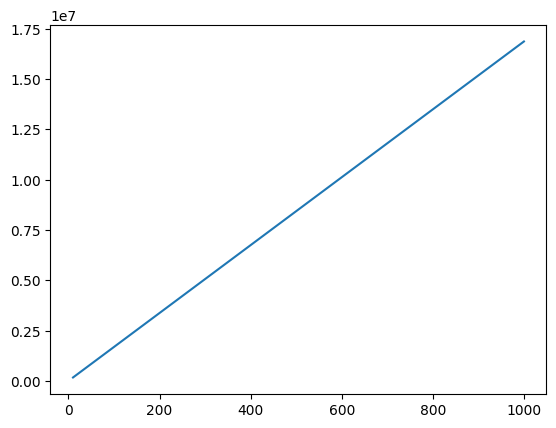

In [71]:
omega = np.linspace(10,1000,10)
F_values = np.array([np.linalg.norm(k) for k in np.array(
    [F(w,y,time_delay,psi) for w in omega])])
print(F_values)
plt.plot(omega, F_values)

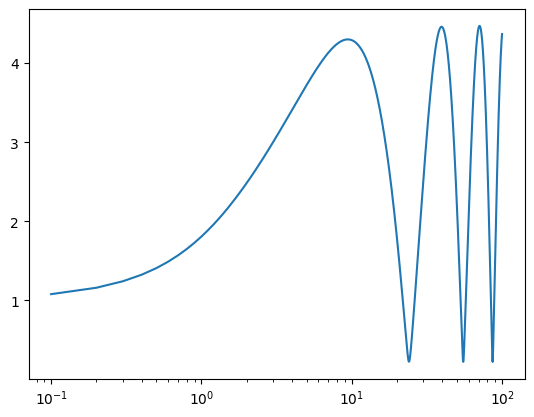

In [125]:
def phi_m(y):
    phi = 1/8*np.linalg.norm(np.sqrt(y**2+4)-y)**2-np.log((y+np.sqrt(y**2+4))/2)
    return phi
    
def  F_pml(omega,y):
    #Need complex to reduce to scalar for mpmath
    exp = complex(np.pi*omega/4 + 1j*omega/2*(np.log(omega/2)-2*phi_m(y)))
    F = (mpmath.exp(exp)*
           mpmath.gamma(1-1j/2*omega)*
           mpmath.hyp1f1(1j/2*omega,1,1j/2*omega*y**2))
    return F

y = 0.1


omega = np.linspace(0.1,100,1000)
F_values = np.array([abs(F_pml(w,y)) for w in omega])

plt.semilogx(omega,F_values)

In [83]:
y = np.array([1])
print(y@y)

1


In [48]:
def h1(t): 
    return np.sin(t) + 1j

def h2(t):
    return np.sin(t) + 3j

def S(t):
    return 3+3j

def inner_p(h1,h2,S,low,high):
    integrand = lambda t: np.conjugate(h1(t)) * h2(t)/S(t)
    a = scipy.integrate.quad(integrand,low,high, complex_func= True)
    return a[0]

def mismatch(h1,h2,S,low,high):
    a = inner_p(h1,h2,S,low,high)
    b = inner_p(h1,h1,S,low,high)
    c = inner_p(h2,h2,S,low,high)

    m = a/np.sqrt(b*c)
    return 1 - m


In [29]:
print(mismatch(h1,h2,S,20,200))

(0.07303303734245448+0.00023264087996811584j)


In [ ]:
plt.plot()